# График моей функции 

(6, matplotlib) Напишите функцию, которая отрисовывает функцию на определенном интервале.

Аргументы функции:
- функция для отрисовки `f`,
- начало интервала отрисовки `min_x`,
- конец интервала отрисовки `max_x`,
- количество точек по оси абсцисс `N`,
- ограничение снизу по оси ординат `min_y`,
- ограничение сверху по оси ординат `max_y`
- цвет кривой красный, кривая непрерывная (1).
- логарифмический масштаб по оси ординат (1)
- сетка (1)

Результат сохранить в файл function.jpeg (1). Дополнительно отрисуйте производную функции на том же графике (2). Параметры отрисовки производной по умолчанию.

In [17]:
import scipy

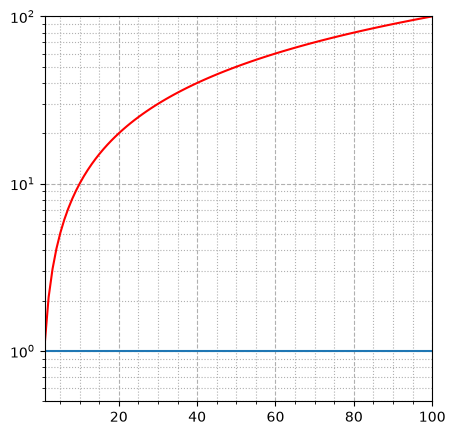

In [ ]:
from math import sqrt
import numpy as np
import pandas as pd
from pandas import Series, DataFrame
import matplotlib.pyplot as plt
from scipy.differentiate import derivative

def cool(f, min_x, max_x, N, min_y, max_y):
    fig, ax = plt.subplots(figsize=(5, 5))

    # plt.axis([0,0.25,0,1.3]) # масштабы осей

    ax.minorticks_on()
    ax.grid(True, which="minor", linestyle=":")
    ax.grid(True, which="major", linestyle="--")

    ax.set_yscale('log')

    ax.set_xlim(min_x, max_x)
    ax.set_ylim(min_y, max_y)

    x = np.linspace(min_x, max_x, N)
    y = np.vectorize(f)(x)

    ax.plot(x, y, c="red")
    res = derivative(np.vectorize(f), x)
    ax.plot(x, res.df)

    plt.savefig("function.jpeg")

    plt.show()

cool(lambda x: x, 1.1, 100, 100, 0.5, 100)
# f' = 1      ^^^^^

# Гистограмма моих данных

(6, numpy/matplotlib) Функция на вход принимает три параметра:

- массив случайных пар `(x, y)` чисел `data`,
- точки разбиения оси абсцисс `x`,
- точки разбиения оси ординат `y`,
- пороговое значение `threshold`

Требования
- Постройте одномерную гистограмму распределения данных (требуется изменить размер входного массива `data` до одномерного) (1.5)
- Сохраните в `histograms_0.png` (0.5).
- Постройте двумерную гистограмму распределения данных при условии: если в корзине (бине/ячейке гистограммы) значение меньше `treshold`, то требуется выставить 0, иначе -- 1 (1.5).
- Сохраните в `histograms_1.png` (0.5).
- Постройте двумерную гистограмму распределения данных при условии: если в корзине (бине/ячейке гистограммы) значение больше `treshold`, то требуется выставить 0, иначе -- значение, которое было в гистограмме (1.5).
- Сохраните в `histograms_2.png` (0.5).
- Не забудьте выставить colorbar (1).

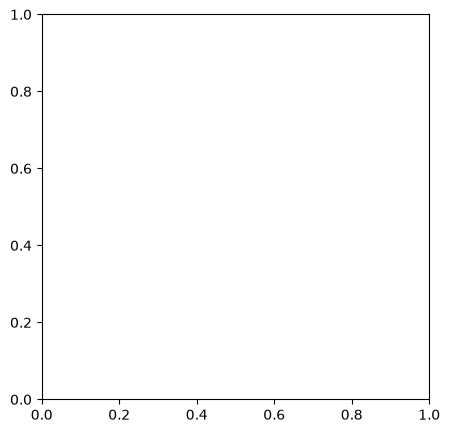

In [ ]:
from math import sqrt
import numpy as np
import pandas as pd
from pandas import Series, DataFrame
import matplotlib.pyplot as plt
from scipy.differentiate import derivative



def cool2(data, x, y, threshold):
    data = np.asarray(data)
    x = np.asarray(x)
    y = np.asarray(y)

    data_1d = data.reshape(-1)

    fig, ax = plt.subplots(figsize=(5, 5))
    ax.hist(data_1d, bins="auto", edgecolor="black")

    fig.savefig("histograms_0.png", dpi=150)
    plt.close(fig)

    # 2
    fig, ax = plt.subplots(figsize=(5, 5))
    hist, _, _ = np.histogram2d(
        data[:, 0],
        data[:, 1],
        bins=[x, y]
    )

    hist_1 = np.where(hist < threshold, 0, 1)
    fig, ax = plt.subplots(figsize=(8, 6))

    mesh = ax.pcolormesh(
        x, y, hist_1.T,
        shading="auto"
    )

    fig.colorbar(mesh, ax=ax, label="Value")
    fig.savefig("histograms_1.png", dpi=150)
    plt.close(fig)

cool2([(0, 1), (0, 2), (0, 3), (1, 1), (1, 2), (0, 4), (0, 3)], [0, 1, 2, 3, 4], [3, 4], 0)

# ~Кино~Игрокритик

Время стать критиком игр (`video-games.csv`). Требуется создать словарь (ключ словаря указан вначале пункта) с соответствующим значением из пункта (тип значения указан в конце строки).

- (1) `"n_games"` Найдите полное количество игр в таблице `int`
- (2) `"by_years"` Определите количество игр за каждый год `pd.DataFrame`
- (2) `"mean_price"` Посчитайте среднюю цену игр, где создатель (`"publisher"`) EA `pd.DataFrame`
- (2) `"age_max_price"` Найдите самые дорогие игры среди игр с разным возрастным рейтингом (`"age_rating"`) `pd.DataFrame`
- (2) `"mean_raiting_1_2"` Найдите средний рейтинг игр, где количество игроков (`"max_players"`) 1 или 2 `float`
- (2) `"min_max_price"` Найдите максимальную и минимальную цену (`"price"`) игр с разным возрастным рейтингом (`"age_rating"`) и среднее значение метрики продаж (`"sales_metric"`). Отсортируйте по убыванию максимальной
цены `pd.DataFrame`
- (2) `"n_games_by_age"` Найдите количество игр в группах с разным рейтингом (`"review_raiting"`) `pd.DataFrame`
- (2) `"same_price_raiting"` Найти игры, у которых совпадает цена (`"price"`) с точностью до округления вниз и совпадает рейтинг (`"review_raiting"`) с точностью до десятков `pd.DataFrame`
- (3) `"creators"` Определите всех возможных создателей игр (`"publisher"`). В ответе не может быть коллабораций создателей `list`
- (4) "max_raiting_by_years" Для каждого года (`"year"`) определите игры (вывести название (`"title"`) в отдельном столбце) с максимальным пользовательским рейтингом (`"review_raiting"`) `pd.DataFrame`
- (1) "empty_creators" Найдите количество игр, у которых отсутствует создатель (`"publisher"`) `int` Ответом является словарь.

In [60]:
df = pd.read_csv("video-games.csv")
#df.head()
d = dict()

In [ ]:
df.groupby('year')['title'].nunique()
df[df.publisher == "EA"].groupby('title')['price'].mean()
df.loc[df.groupby('age_raiting')['price'].idxmax(), 'title']
df[(df.max_players == 1) | (df.max_players == 2)]['review_raiting'].mean()
#?
df.groupby('review_raiting')['console'].value_counts()

# import math
# df["price_floored"] = df["price"].apply(math.floor)
# df["review_floored"] = df["review_raiting"].apply(math.floor)
# df.groupby(["price_floored", "review_floored"])['title'].sum()


# ----



d["n_games"] = int(len(df))

d["by_years"] = (
    df.groupby("year")
    .size()
    .reset_index(name="n_games")
)

d["mean_price"] = (
    df[df["publisher"] == "EA"]
    .groupby("publisher")[["price"]]
    .mean()
    .rename(columns={"price": "mean_price"})
)

d["age_max_price"] = (
    df[
        df["price"] == df.groupby("age_raiting")["price"]
        .transform("max")
    ][["age_raiting", "title", "price"]]
    .sort_values(["age_raiting", "title"])
    .reset_index(drop=True)
)

d["mean_raiting_1_2"] = float(
    df[df["max_players"].isin([1, 2])]["review_raiting"].mean()
)

d["min_max_price"] = (
    df.groupby("age_raiting")
    .agg(
        min_price=("price", "min"),
        max_price=("price", "max"),
        mean_sales_metric=("sales_metric", "mean")
    )
    .sort_values("max_price", ascending=False)
    .reset_index()
)

d["n_games_by_age"] = (
    df.groupby("review_raiting")
    .size()
    .reset_index(name="n_games")
)


d["same_price_raiting"] = (
    df.assign(
        price_floor=np.floor(df["price"]),
        rating_tens=np.floor(df["review_raiting"])
    )
    .loc[lambda x: x.duplicated(
        ["price_floor", "rating_tens"], keep=False
    )]
    .sort_values(["price_floor", "rating_tens", "title"])
    .drop(columns=["price_floor", "rating_tens"])
    .reset_index(drop=True)
)

d["creators"] = sorted({
    creator.strip()
    for publisher in df["publisher"].dropna()
    for creator in publisher.split(",")
    if creator.strip()
})

d["max_raiting_by_years"] = (
    df[
        df["review_raiting"] ==
        df.groupby("year")["review_raiting"].transform("max")
    ][["year", "title", "review_raiting"]]
    .sort_values(["year", "title"])
    .reset_index(drop=True)
),

d["empty_creators"] = int(df["publisher"].isna().sum())

In [25]:
df.head()

,Unnamed: 0,title,max_players,genres,publisher,sales_metric,price,review_raiting,console,age_raiting,year
0,0,Super Mario 64 DS,1,Action,Nintendo,4.69,24.95,85,Nintendo DS,E,2004
1,1,Lumines: Puzzle Fusion,1,Strategy,Ubisoft,0.56,14.95,89,Sony PSP,E,2004
2,2,WarioWare Touched!,2,"Action,Racing / Driving,Sports",Nintendo,0.54,22.95,81,Nintendo DS,E,2004
3,3,Hot Shots Golf: Open Tee,1,Sports,Sony,0.49,12.95,81,Sony PSP,E,2004
4,4,Spider-Man 2,1,Action,Activision,0.45,14.95,61,Nintendo DS,E,2004
